In [86]:
import os
import pandas as pd
import numpy as np
import random, time
import matplotlib.pyplot as plt
from tqdm import tqdm
import ipywidgets as widgets
from IPython.display import display, clear_output

# =====================================================
# 1️⃣ Portfolio evaluation
# =====================================================
def evaluate_portfolio(weights, returns, rf=0.0):
    weights = np.array(weights)
    weights = weights / np.sum(weights)
    mean_r = returns.mean()
    cov = returns.cov()
    port_r = np.sum(mean_r * weights) * 252
    port_v = np.sqrt(np.dot(weights.T, np.dot(cov * 252, weights)))
    sharpe = (port_r - rf) / port_v if port_v > 0 else 0.0
    return sharpe, port_r, port_v

def safe_normalize(arr):
    total = np.sum(arr)
    if total == 0 or np.isnan(total):
        arr = np.random.rand(len(arr))
        total = np.sum(arr)
    return arr / total

# =====================================================
# 2️⃣ Genetic Algorithm core
# =====================================================
def run_ga(returns, population_size=50, generations=100,
           mutation_rate=0.2, step=0.05, verbose=False):
    """Run Genetic Algorithm optimization for portfolio."""
    n_stocks = returns.shape[1]
    possible = np.arange(0, 1.05, step)

    def init_population():
        pop = []
        for _ in range(population_size):
            w = np.random.choice(possible, n_stocks)
            w = safe_normalize(w)
            pop.append(w)
        return pop

    def mutate(child):
        if random.random() < mutation_rate:
            idx = random.randint(0, len(child)-1)
            child[idx] += np.random.choice([-step, step])
            child = np.clip(child, 0, 1)
            child = np.round(child / step) * step
            child = safe_normalize(child)
        return child

    def crossover(p1, p2):
        pt = random.randint(1, len(p1)-1)
        child = np.concatenate((p1[:pt], p2[pt:]))
        child = np.abs(child)
        child = safe_normalize(child)
        return child

    pop = init_population()
    best_portfolio = None
    fitness_progress = []  # track best Sharpe per generation
    start = time.time()

    for g in range(generations):
        fits = [evaluate_portfolio(ind, returns)[0] for ind in pop]
        elite_idx = np.argmax(fits)
        best_portfolio = pop[elite_idx]
        fitness_progress.append(fits[elite_idx])

        new_pop = [best_portfolio]
        for _ in range(population_size - 1):
            p1, p2 = random.choices(pop, k=2)
            child = mutate(crossover(p1, p2))
            new_pop.append(child)
        pop = new_pop

        if verbose and g % 10 == 0:
            print(f"Gen {g+1}/{generations} → Best Sharpe {fits[elite_idx]:.4f}")

    end = time.time()
    sharpe, ret, vol = evaluate_portfolio(best_portfolio, returns)
    return {
        "weights": best_portfolio,
        "sharpe": sharpe,
        "return": ret,
        "risk": vol,
        "runtime": end - start,
        "population": pop,
        "progress": fitness_progress
    }

# =====================================================
# 3️⃣ Wisdom of Crowds aggregation
# =====================================================
def apply_woc(population, returns, crowd_size=10, method="mean"):
    fits = np.array([evaluate_portfolio(ind, returns)[0] for ind in population])
    top_idx = np.argsort(fits)[-crowd_size:]
    top_pop = np.array(population)[top_idx]

    if method == "mean":
        agg = top_pop.mean(axis=0)
    elif method == "median":
        agg = np.median(top_pop, axis=0)
    else:  # vote method
        votes = (top_pop > 0).sum(axis=0)
        agg = votes / votes.sum()

    agg = safe_normalize(agg)
    sharpe, ret, vol = evaluate_portfolio(agg, returns)
    return {"weights": agg, "sharpe": sharpe, "return": ret, "risk": vol}

# =====================================================
# 4️⃣ Visualization helpers
# =====================================================
def plot_allocations(weights, columns, title="Top 20 Stocks"):
    top = pd.Series(weights, index=columns).sort_values(ascending=False).head(20)
    top.plot(kind="barh", color="teal", figsize=(9,5))
    plt.title(title)
    plt.xlabel("Weight")
    plt.grid(axis="x", alpha=0.4)
    plt.tight_layout()
    plt.show()

def plot_progress(progress):
    plt.figure(figsize=(8,4))
    plt.plot(progress, color='darkorange', linewidth=2)
    plt.title("GA Optimization Progress (Sharpe Ratio per Generation)")
    plt.xlabel("Generation")
    plt.ylabel("Best Sharpe Ratio")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# =====================================================
# 5️⃣ Run + Compare (Train/Test version)
# =====================================================
results_train, results_test = [], []

def run_experiment_gui(train_returns, test_returns,
                       population_size, generations, mutation_rate, step, crowd_size):
    print("🚀 Running GA optimization on TRAIN data...")
    ga_res = run_ga(train_returns,
                    population_size=population_size,
                    generations=generations,
                    mutation_rate=mutation_rate,
                    step=step)

    print(f"✅ GA (TRAIN) → Sharpe={ga_res['sharpe']:.3f} | "
          f"Return={ga_res['return']*100:.2f}% | Risk={ga_res['risk']*100:.2f}% "
          f"| Runtime={ga_res['runtime']:.2f}s")

    print("\n🧠 Applying Wisdom of Crowds (WoC)...")
    woc_start = time.time()
    woc_res = apply_woc(ga_res["population"], train_returns, crowd_size=crowd_size)
    woc_time = time.time() - woc_start

    print(f"✅ WoC (TRAIN) → Sharpe={woc_res['sharpe']:.3f} | "
          f"Return={woc_res['return']*100:.2f}% | Risk={woc_res['risk']*100:.2f}% "
          f"| Runtime={woc_time:.2f}s")

    # --- Evaluate on TEST data ---
    ga_test_sharpe, ga_test_ret, ga_test_vol = evaluate_portfolio(ga_res["weights"], test_returns)
    woc_test_sharpe, woc_test_ret, woc_test_vol = evaluate_portfolio(woc_res["weights"], test_returns)

    print("\n📈 TEST PERFORMANCE (using TRAIN-optimized portfolios):")
    print(f"GA → Sharpe={ga_test_sharpe:.3f}, Return={ga_test_ret*100:.2f}%, Risk={ga_test_vol*100:.2f}%")
    print(f"WoC → Sharpe={woc_test_sharpe:.3f}, Return={woc_test_ret*100:.2f}%, Risk={woc_test_vol*100:.2f}%")

    # --- Record results ---
    results_train.append({
        "Population": population_size,
        "Generations": generations,
        "Mutation": mutation_rate,
        "Step": step,
        "Crowd": crowd_size,
        "GA_Return(%)": ga_res["return"]*100,
        "GA_Risk(%)": ga_res["risk"]*100,
        "GA_Sharpe": ga_res["sharpe"],
        "GA_Runtime(s)": ga_res["runtime"],
        "WOC_Return(%)": woc_res["return"]*100,
        "WOC_Risk(%)": woc_res["risk"]*100,
        "WOC_Sharpe": woc_res["sharpe"],
        "WOC_Runtime(s)": woc_time
    })
    results_test.append({
        "Population": population_size,
        "Generations": generations,
        "Mutation": mutation_rate,
        "Step": step,
        "Crowd": crowd_size,
        "GA_Return(%)": ga_test_ret*100,
        "GA_Risk(%)": ga_test_vol*100,
        "GA_Sharpe": ga_test_sharpe,
        "WOC_Return(%)": woc_test_ret*100,
        "WOC_Risk(%)": woc_test_vol*100,
        "WOC_Sharpe": woc_test_sharpe
    })

    # --- Visualization ---
    plot_progress(ga_res["progress"])
    print("\n--- GA Portfolio Allocation (TRAIN) ---")
    plot_allocations(ga_res["weights"], train_returns.columns, "GA Portfolio: Top 20 (Train)")
    print("\n--- GA+WoC Portfolio Allocation (TRAIN) ---")
    plot_allocations(woc_res["weights"], train_returns.columns, "GA+WoC Portfolio: Top 20 (Train)")

    # --- Display results ---
    print("\n📊 Summary of Train Experiments:")
    display(pd.DataFrame(results_train))
    print("\n📈 Summary of Test Performance:")
    display(pd.DataFrame(results_test))

    # --- Save results ---
    pd.DataFrame(results_train).to_csv("results_train.csv", index=False)
    pd.DataFrame(results_test).to_csv("results_test.csv", index=False)
    np.save("best_ga_weights.npy", ga_res["weights"])
    np.save("best_woc_weights.npy", woc_res["weights"])
    print("💾 Results and weights saved (CSV + NPY)\n")

# =====================================================
# 6️⃣ Interactive GUI
# =====================================================
def interactive_gui(train_returns, test_returns):
    pop_slider = widgets.IntSlider(50, 20, 200, 10, description='Population')
    gen_slider = widgets.IntSlider(100, 20, 300, 10, description='Generations')
    mut_slider = widgets.FloatSlider(value=0.2, min=0.05, max=0.5, step=0.05, description='Mutation')
    step_slider = widgets.FloatSlider(value=0.05, min=0.01, max=0.2, step=0.01, description='Step')
    crowd_slider = widgets.IntSlider(10, 5, 50, 5, description='Crowd size')

    ui = widgets.VBox([pop_slider, gen_slider, mut_slider, step_slider, crowd_slider])
    out = widgets.Output()

    def on_run(_):
        with out:
            clear_output()
            run_experiment_gui(train_returns, test_returns,
                               pop_slider.value, gen_slider.value,
                               mut_slider.value, step_slider.value,
                               crowd_slider.value)

    run_button = widgets.Button(description="Run Experiment", button_style='success', icon="play")
    run_button.on_click(on_run)
    display(ui, run_button, out)



In [76]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm

# ======================================================
# 1️⃣ LOAD STOCK FILES
# ======================================================
data_path = "/kaggle/input/sandp500/individual_stocks_5yr/individual_stocks_5yr"
all_files = sorted([f for f in os.listdir(data_path) if f.endswith(".csv")])
print(f"📁 Found {len(all_files)} stock files.\n")

price_data = {}
for file in tqdm(all_files, desc="Loading full-length stocks"):
    try:
        df = pd.read_csv(os.path.join(data_path, file), usecols=["date", "close"])
        if len(df) == 1259:
            ticker = file.replace("_data.csv", "").upper()
            df["date"] = pd.to_datetime(df["date"])
            price_data[ticker] = df
    except Exception as e:
        print(f"⚠️ Error reading {file}: {e}")

print(f"✅ Loaded {len(price_data)} valid stocks.\n")

# ======================================================
# 2️⃣ MERGE + COMPUTE RETURNS
# ======================================================
merged = None
for t, df in price_data.items():
    df = df.rename(columns={"close": t})
    merged = df if merged is None else pd.merge(merged, df, on="date", how="outer")

merged = merged.sort_values("date").ffill().dropna()
returns = merged.copy()
returns.set_index("date", inplace=True)
returns = returns.pct_change().dropna()

# ======================================================
# 3️⃣ SPLIT TRAIN / TEST (4 yrs train, 1 yr test)
# ======================================================
train_returns = returns.iloc[:1007]
test_returns  = returns.iloc[1007:]

print(f"✅ Train returns: {train_returns.shape} | Test returns: {test_returns.shape}")


📁 Found 505 stock files.



Loading full-length stocks: 100%|██████████| 505/505 [00:02<00:00, 241.62it/s]


✅ Loaded 470 valid stocks.

✅ Train returns: (1007, 470) | Test returns: (251, 470)


In [85]:
interactive_gui(train_returns, test_returns)

Button(button_style='success', description='Run Experiment', icon='play', style=ButtonStyle())

Output()

In [88]:

best_weights = np.load("best_woc_weights.npy")


📊 ====== OUT-OF-SAMPLE (TEST) COMPARISON ======
GA+WoC  → Return: 40.81% | Risk: 21.26% | Sharpe: 1.920
S&P 500 → Return: 15.60% | Risk: 8.46% | Sharpe: 1.844



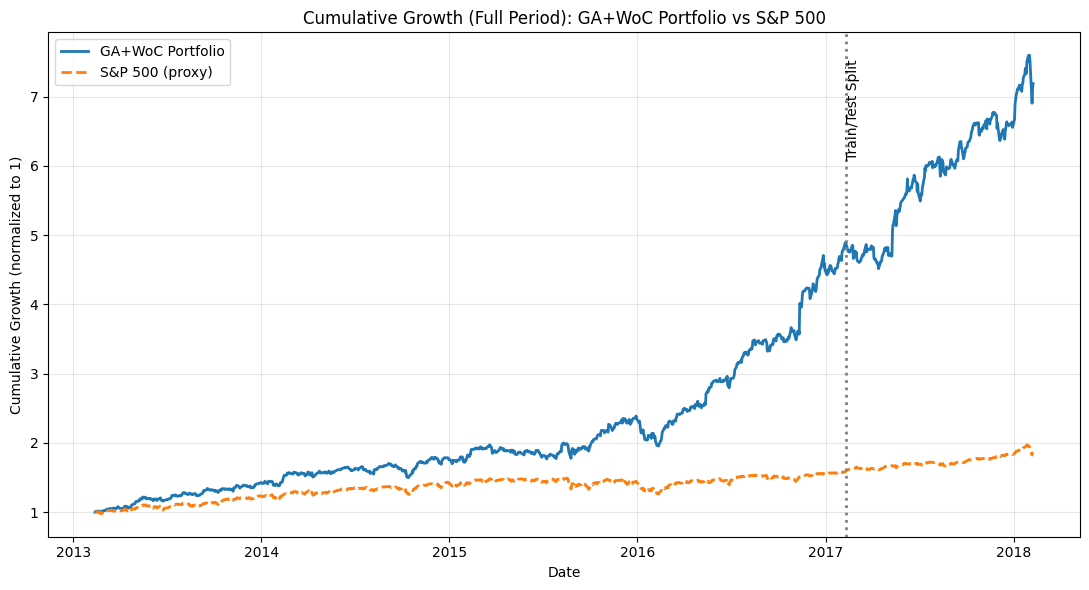

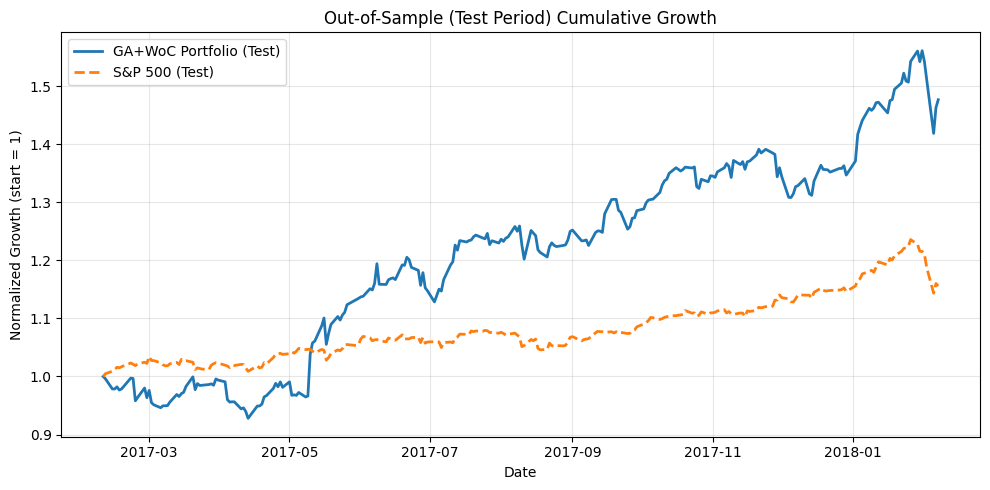

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ========= 1) Build / align the S&P 500 proxy index =========
index_path = "/kaggle/input/sandp500/all_stocks_5yr.csv"
sp500 = pd.read_csv(index_path, usecols=["date", "close"])
sp500["date"] = pd.to_datetime(sp500["date"])
index_df = sp500.groupby("date")["close"].mean().reset_index(name="sp500_close")

# Align to returns
index_df = index_df.set_index("date").sort_index()
index_df = index_df.loc[index_df.index.intersection(returns.index)]
index_returns = index_df["sp500_close"].pct_change().dropna()

# ========= 2) Recompute GA cumulative growth =========
ga_daily = returns.dot(best_weights)
ga_cum = (1 + ga_daily).cumprod()
idx_cum = (1 + index_returns).cumprod()

# ========= 3) Align both series to same date range =========
common_dates = ga_cum.index.intersection(idx_cum.index)
ga_cum = ga_cum.loc[common_dates]
idx_cum = idx_cum.loc[common_dates]
ga_daily = ga_daily.loc[common_dates]
index_returns = index_returns.loc[common_dates]

# ========= 4) Define train/test split =========
split_date = train_returns.index[-1]
test_mask = ga_cum.index > split_date

# ========= 5) Compute test-period metrics =========
def ann_metrics(daily_ret, rf=0.0):
    mean_d, std_d = daily_ret.mean(), daily_ret.std()
    ann_ret = mean_d * 252
    ann_vol = std_d * np.sqrt(252)
    sharpe = (ann_ret - rf) / ann_vol if ann_vol > 0 else 0.0
    return ann_ret, ann_vol, sharpe

ga_test_ret, ga_test_vol, ga_test_sharpe = ann_metrics(ga_daily.loc[test_mask])
idx_test_ret, idx_test_vol, idx_test_sharpe = ann_metrics(index_returns.loc[test_mask])

print("📊 ====== OUT-OF-SAMPLE (TEST) COMPARISON ======")
print(f"GA+WoC  → Return: {ga_test_ret*100:.2f}% | Risk: {ga_test_vol*100:.2f}% | Sharpe: {ga_test_sharpe:.3f}")
print(f"S&P 500 → Return: {idx_test_ret*100:.2f}% | Risk: {idx_test_vol*100:.2f}% | Sharpe: {idx_test_sharpe:.3f}")
print("================================================\n")

# ========= 6) Plot 1: Full period (train + test) =========
plt.figure(figsize=(11,6))
ga_cum_norm = ga_cum / ga_cum.iloc[0]
idx_cum_norm = idx_cum / idx_cum.iloc[0]

plt.plot(ga_cum_norm.index, ga_cum_norm, linewidth=2, label="GA+WoC Portfolio")
plt.plot(idx_cum_norm.index, idx_cum_norm, linewidth=2, linestyle="--", label="S&P 500 (proxy)")
plt.axvline(split_date, linestyle=":", color="gray", linewidth=2)
plt.text(split_date, plt.ylim()[1]*0.95, "Train/Test Split", rotation=90, va="top", ha="left", fontsize=10)
plt.title("Cumulative Growth (Full Period): GA+WoC Portfolio vs S&P 500")
plt.xlabel("Date")
plt.ylabel("Cumulative Growth (normalized to 1)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ========= 7) Plot 2: Test-only performance =========
plt.figure(figsize=(10,5))
ga_test_cum = (1 + ga_daily.loc[test_mask]).cumprod()
idx_test_cum = (1 + index_returns.loc[test_mask]).cumprod()

# Normalize both to start = 1 at test start
start_date = ga_test_cum.index[0]
ga_test_cum /= ga_test_cum.loc[start_date]
idx_test_cum /= idx_test_cum.loc[start_date]

plt.plot(ga_test_cum.index, ga_test_cum.values, label="GA+WoC Portfolio (Test)", linewidth=2)
plt.plot(idx_test_cum.index, idx_test_cum.values, label="S&P 500 (Test)", linestyle="--", linewidth=2)
plt.title("Out-of-Sample (Test Period) Cumulative Growth")
plt.xlabel("Date")
plt.ylabel("Normalized Growth (start = 1)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
